In [24]:
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})


@dataclass(slots=True)
class Envelope:
    x: np.ndarray = field(default_factory=lambda: np.empty(0))
    y: np.ndarray = field(default_factory=lambda: np.empty(0))
    label: str = ""


def format_n_label(n_series: pd.Series) -> str:
    """Формирует корректную подпись номеров гармоник по фактическим данным."""
    ns = list(n_series)
    if len(ns) == 1:
        return f"Измеренная гармоника (n = {ns[0]})"
    if ns == list(range(ns[0], ns[-1] + 1)):
        return f"Измеренные гармоники (n = {ns[0]}..{ns[-1]})"
    return f"Измеренные гармоники (n = {', '.join(map(str, ns))})"


def plot_spectrum(
    harmonics: pd.DataFrame,
    title: str,
    envelope: Envelope | None = None,
    level_line: tuple[float, str] | None = None,
    vlines: list[tuple[float, str]] | None = None,
    y_col: str = "A, mV",
    y_label: str = "Амплитуда $A$, мВ",
) -> None:
    plt.figure()
    plt.stem(
        harmonics["freq, kHz"],
        harmonics[y_col],
        linefmt="b-",
        markerfmt="bo",
        basefmt=" ",
        label=format_n_label(harmonics["n"]),
    )

    if envelope is not None and envelope.x.size > 0:
        plt.plot(
            envelope.x,
            envelope.y,
            "r--",
            linewidth=2,
            label=envelope.label,
        )

    if level_line is not None:
        y_val, lbl = level_line
        plt.axhline(y_val, color="g", linestyle=":", linewidth=1.5, label=lbl)

    if vlines:
        for x_val, lbl in vlines:
            plt.axvline(x_val, color="m", linestyle="-.", linewidth=1.5, label=lbl)

    plt.title(title)
    plt.xlabel(r"Частота $\nu$, кГц")
    plt.ylabel(y_label)
    plt.xlim(left=0)
    plt.ylim(bottom=0)
    plt.legend()
    plt.tight_layout()
    plt.show()


def analyze_power_signal(
    name: str,
    harmonics: pd.DataFrame,
    T: float,
    tau: float | None = None,
    power: int | None = None,
) -> dict:
    """
    Печатает таблицу гармоник, проверяет T vs 1/f1,
    подгоняет огибающую A(f) = k / f^power и строит график.
    """
    df = harmonics.copy()
    f1 = float(df["freq, kHz"].iloc[0])
    A1 = float(df["A, mV"].iloc[0])
    df["A/A1"] = (df["A, mV"] / A1).round(3)

    T_spec = 1.0 / (f1 * 1e3)
    rel_diff = abs(T - T_spec) / T * 100

    print(f"=== {name} ===")
    print(df.to_string(index=False))
    print(
        f"Период (осциллограф): T = {T*1e6:.2f} мкс | "
        f"по спектру 1/ν1 = {T_spec*1e6:.2f} мкс (расхождение {rel_diff:.2f}%)"
    )

    env = None
    level_line = None
    vlines = None
    result = {"T": T, "f1": f1, "A1": A1}

    if power is not None:
        model = lambda f, k: k / (f ** power)
        (k_fit,), _ = curve_fit(
            model,
            df["freq, kHz"].to_numpy(),
            df["A, mV"].to_numpy(),
            p0=[A1 * (f1 ** power)],
        )

        f_max = float(df["freq, kHz"].max())
        f_grid = np.linspace(f1, f_max * 1.1, 300)
        env_label = (
            r"Аппроксимация $A(\nu) = k/\nu$"
            if power == 1
            else rf"Аппроксимация $A(\nu) = k/\nu^{power}$"
        )
        env = Envelope(f_grid, model(f_grid, k_fit), env_label)

        # Ширина спектра по пересечению аппроксимированной огибающей с уровнем A1/e
        level_e = A1 / np.e
        df_exp = (k_fit / level_e) ** (1.0 / power)
        level_line = (level_e, f"Уровень $A_1/e$ ({level_e:.1f} мВ)")
        vlines = [(df_exp, rf"$\Delta\nu_{{1/e}} = {df_exp:.2f}$ кГц")]

        print(f"Ширина спектра (по уровню A1/e): Δν = {df_exp:.2f} кГц")
        if tau is not None:
            prod = (df_exp * 1e3) * tau
            print(
                f"Длительность импульса τ = {tau*1e6:.2f} мкс | "
                f"Δν · τ = {prod:.2f}"
            )
            result["df_exp"] = df_exp
            result["product"] = prod

    plot_spectrum(
        df,
        title=f"Спектр сигнала: {name}",
        envelope=env,
        level_line=level_line,
        vlines=vlines,
    )
    return result

**Часть 1. Фиксированные сигналы генератора**

=== Прямоугольный сигнал (меандр) ===
 n  freq, kHz  A, mV  A/A1
 1      8.084 886.10 1.000
 3     24.060 277.60 0.313
 5     40.030 160.10 0.181
 7     56.080 128.10 0.145
 9     72.050  85.41 0.096
Период (осциллограф): T = 124.57 мкс | по спектру 1/ν1 = 123.70 мкс (расхождение 0.70%)
Ширина спектра (по уровню A1/e): Δν = 21.72 кГц
Длительность импульса τ = 62.28 мкс | Δν · τ = 1.35


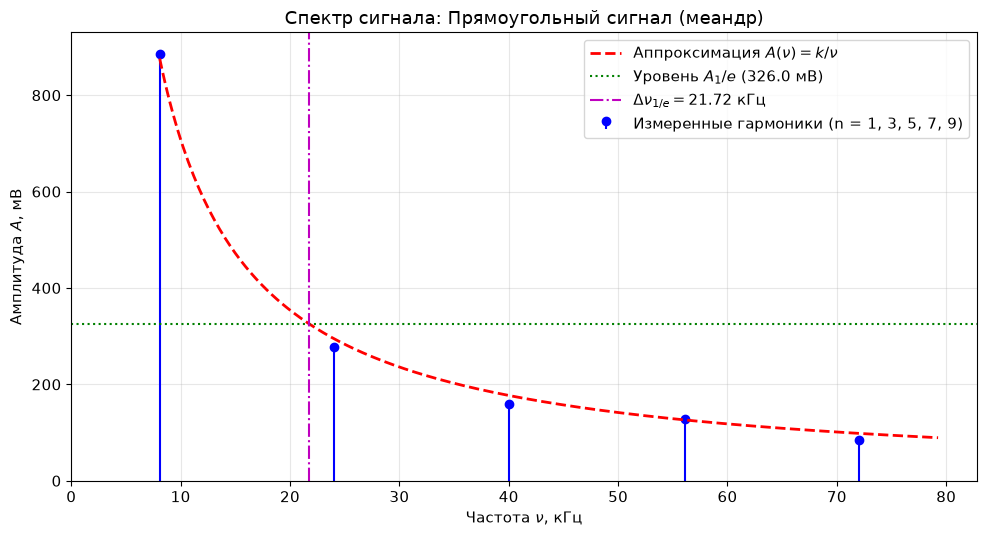

=== Синусоидальный сигнал ===
 n  freq, kHz  A, mV  A/A1
 1      8.084  697.5   1.0
Период (осциллограф): T = 125.30 мкс | по спектру 1/ν1 = 123.70 мкс (расхождение 1.28%)


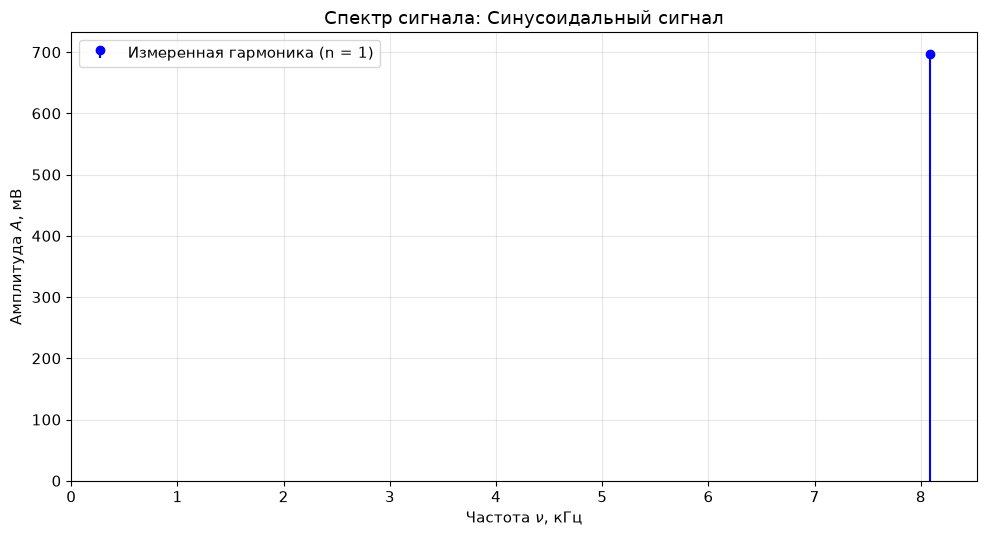

=== Треугольный сигнал ===
 n  freq, kHz  A, mV  A/A1
 1      7.935 573.00 1.000
 3     24.130  74.73 0.130
 5     39.960  17.79 0.031
Период (осциллограф): T = 125.30 мкс | по спектру 1/ν1 = 126.02 мкс (расхождение 0.58%)
Ширина спектра (по уровню A1/e): Δν = 13.10 кГц
Длительность импульса τ = 62.65 мкс | Δν · τ = 0.82


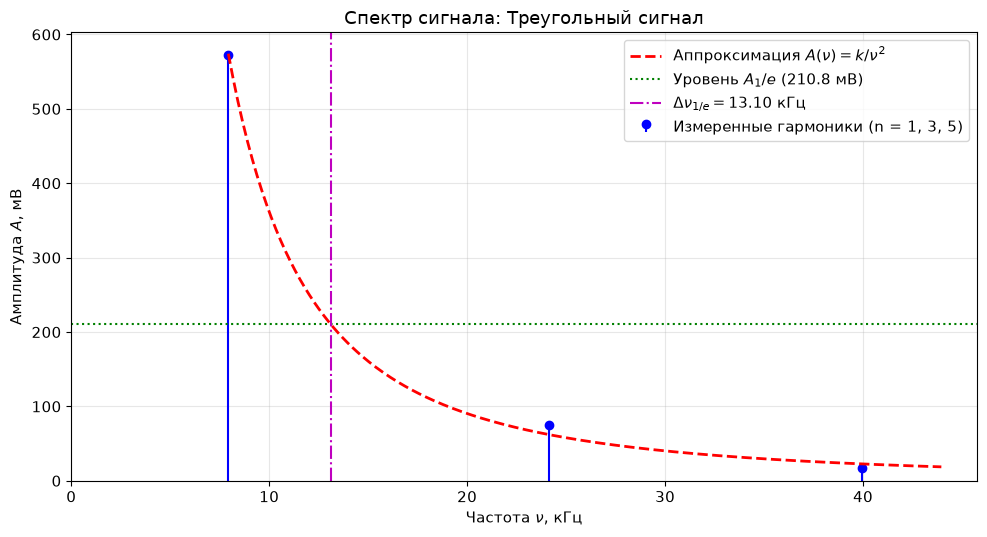

=== Пилообразный сигнал (повышающийся) ===
 n  freq, kHz  A, mV  A/A1
 1      8.084 441.30 1.000
 2     15.920 220.60 0.500
 3     24.060 131.70 0.298
 4     32.040  99.64 0.226
 5     39.880  74.73 0.169
 6     48.020  60.50 0.137
Период (осциллограф): T = 124.95 мкс | по спектру 1/ν1 = 123.70 мкс (расхождение 1.00%)
Ширина спектра (по уровню A1/e): Δν = 21.46 кГц
Длительность импульса τ = 62.48 мкс | Δν · τ = 1.34


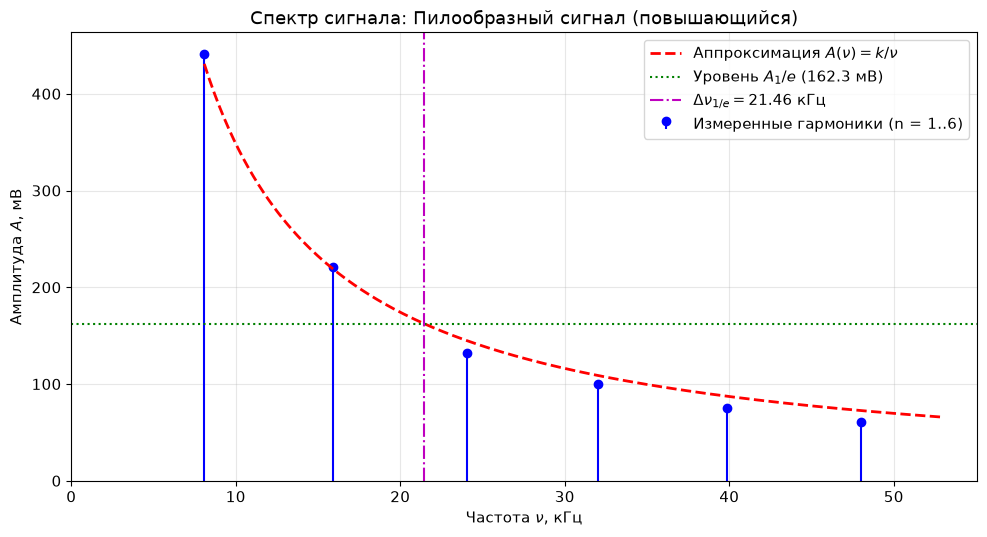

=== Пилообразный сигнал (понижающийся) ===
 n  freq, kHz  A, mV  A/A1
 1       7.86 448.40 1.000
 2      16.00 227.80 0.508
 3      24.43 153.00 0.341
 4      31.97  99.64 0.222
 5      40.03  78.29 0.175
 6      48.09  71.17 0.159
Период (осциллограф): T = 124.59 мкс | по спектру 1/ν1 = 127.23 мкс (расхождение 2.12%)
Ширина спектра (по уровню A1/e): Δν = 21.42 кГц
Длительность импульса τ = 62.29 мкс | Δν · τ = 1.33


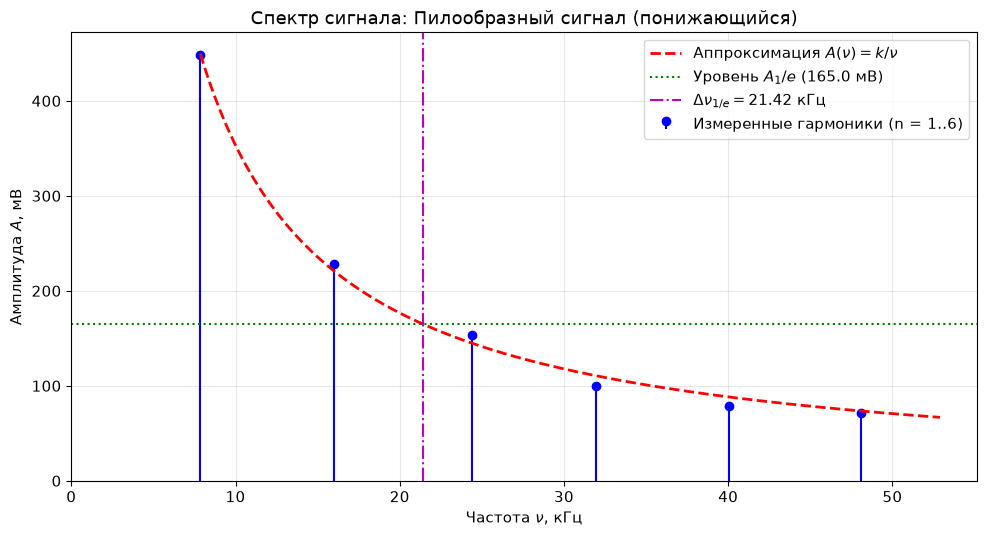

{'T': 0.000124586,
 'f1': 7.86,
 'A1': 448.4,
 'df_exp': np.float64(21.418766220413442),
 'product': np.float64(1.3342392041682145)}

In [25]:
# 1.1. Прямоугольный сигнал (меандр)
harm_square = pd.DataFrame({
    "n": [1, 3, 5, 7, 9],
    "freq, kHz": [8.084, 24.06, 40.03, 56.08, 72.05],
    "A, mV": [886.1, 277.6, 160.1, 128.1, 85.41],
})
T_square = (127.3 - 2.732) * 1e-6
analyze_power_signal(
    "Прямоугольный сигнал (меандр)",
    harm_square,
    T=T_square,
    tau=T_square / 2,
    power=1,
)

# 1.2. Синусоидальный сигнал
harm_sine = pd.DataFrame({
    "n": [1],
    "freq, kHz": [8.084],
    "A, mV": [697.5],
})
T_sine = (156.7 - 31.4) * 1e-6
analyze_power_signal("Синусоидальный сигнал", harm_sine, T=T_sine)

# 1.3. Треугольный сигнал
harm_tri = pd.DataFrame({
    "n": [1, 3, 5],
    "freq, kHz": [7.935, 24.13, 39.96],
    "A, mV": [573.0, 74.73, 17.79],
})
T_tri = (156.7 - 31.4) * 1e-6
analyze_power_signal(
    "Треугольный сигнал",
    harm_tri,
    T=T_tri,
    tau=T_tri / 2,
    power=2,
)

# 1.4. Пилообразный сигнал (повышающийся)
harm_saw_up = pd.DataFrame({
    "n": [1, 2, 3, 4, 5, 6],
    "freq, kHz": [8.084, 15.92, 24.06, 32.04, 39.88, 48.02],
    "A, mV": [441.3, 220.6, 131.7, 99.64, 74.73, 60.5],
})
T_saw_up = (187.3 - 62.35) * 1e-6
analyze_power_signal(
    "Пилообразный сигнал (повышающийся)",
    harm_saw_up,
    T=T_saw_up,
    tau=T_saw_up / 2,
    power=1,
)

# 1.5. Пилообразный сигнал (понижающийся)
harm_saw_down = pd.DataFrame({
    "n": [1, 2, 3, 4, 5, 6],
    "freq, kHz": [7.86, 16.0, 24.43, 31.97, 40.03, 48.09],
    "A, mV": [448.4, 227.8, 153.0, 99.64, 78.29, 71.17],
})
T_saw_down = (127.7 - 3.114) * 1e-6
analyze_power_signal(
    "Пилообразный сигнал (понижающийся)",
    harm_saw_down,
    T=T_saw_down,
    tau=T_saw_down / 2,
    power=1,
)

**Сравнение двух пилообразных сигналов и теоретической спектральной плотности**

In [26]:
saw_compare = pd.DataFrame({
    "n": harm_saw_up["n"],
    "A_пов / A1": (harm_saw_up["A, mV"] / harm_saw_up["A, mV"].iloc[0]).round(3),
    "A_пон / A1": (harm_saw_down["A, mV"] / harm_saw_down["A, mV"].iloc[0]).round(3),
    "Теория (1/n)": (1.0 / harm_saw_up["n"]).round(3),
})
print("=== Сравнение пилообразных сигналов с расчётом |ρ(ω_n)| ∝ 1/n ===")
print(saw_compare.to_string(index=False))

=== Сравнение пилообразных сигналов с расчётом |ρ(ω_n)| ∝ 1/n ===
 n  A_пов / A1  A_пон / A1  Теория (1/n)
 1       1.000       1.000         1.000
 2       0.500       0.508         0.500
 3       0.298       0.341         0.333
 4       0.226       0.222         0.250
 5       0.169       0.175         0.200
 6       0.137       0.159         0.167


**Гауссовский импульс**

=== Гауссовский импульс ===
 n  freq, kHz  A, mV
 0      0.970 807.80
 1      8.084 637.00
 2     16.700 277.00
 3     23.980  74.73
Период T = 125.35 мкс (1/ν1 = 123.70 мкс)
Аппроксимация: A0 = 813.2 мВ, Δν_(1/e) = 16.00 кГц
Полуширина спектра на полувысоте: Δν_0.5 = 13.32 кГц
Ожидаемая по спектру длительность импульса: τ_0.5 ≈ 33.13 мкс
По текущим t1, t2: τ_0.5 = 36.50 мкс | Δν_0.5 · τ_0.5 = 0.49 (теория: 0.44)


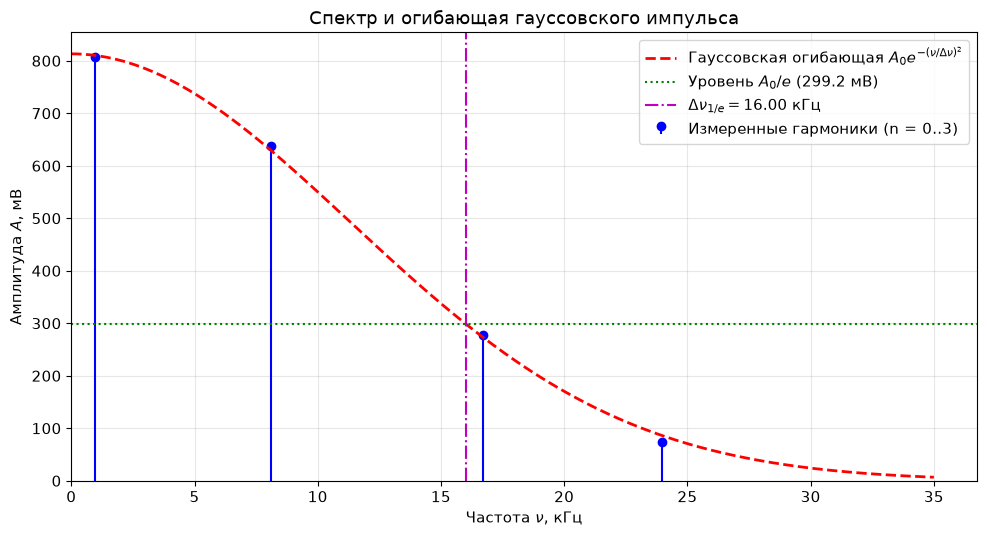

In [27]:
harm_gauss = pd.DataFrame({
    "n": [0, 1, 2, 3],
    # 0-я гармоника (постоянная составляющая) смещена из-за конечного разрешения БПФ
    "freq, kHz": [0.97, 8.084, 16.7, 23.98],
    "A, mV": [807.8, 637.0, 277.0, 74.73],
})
T_gauss = (142.6 - 17.25) * 1e-6


def gauss_env(f, A0, df_e):
    return A0 * np.exp(-((f / df_e) ** 2))


# Для честной аппроксимации огибающей подставляем частоту 0 для n=0
f_for_fit = harm_gauss["freq, kHz"].to_numpy().copy()
f_for_fit[0] = 0.0

(A0_fit, df_e_fit), _ = curve_fit(
    gauss_env,
    f_for_fit,
    harm_gauss["A, mV"].to_numpy(),
    p0=(808.0, 16.0),
)

# Полуширина спектра на полувысоте (0.5 от A0)
df_half = df_e_fit * np.sqrt(np.log(2))

# Теоретическое соотношение для гауссова импульса:
# df_half (от 0 до уровня 0.5) * tau_half (полная ширина на уровне 0.5) = 2*ln(2)/pi ≈ 0.441
theory_prod = 2 * np.log(2) / np.pi
tau_half_expected = theory_prod / (df_half * 1e3)

t1_us = 0
t2_us = 36.5
tau_half_meas = (t2_us - t1_us) * 1e-6

print("=== Гауссовский импульс ===")
print(harm_gauss.to_string(index=False))
print(f"Период T = {T_gauss*1e6:.2f} мкс (1/ν1 = {1e3/8.084:.2f} мкс)")
print(f"Аппроксимация: A0 = {A0_fit:.1f} мВ, Δν_(1/e) = {df_e_fit:.2f} кГц")
print(f"Полуширина спектра на полувысоте: Δν_0.5 = {df_half:.2f} кГц")
print(f"Ожидаемая по спектру длительность импульса: τ_0.5 ≈ {tau_half_expected*1e6:.2f} мкс")
print(
    f"По текущим t1, t2: τ_0.5 = {tau_half_meas*1e6:.2f} мкс | "
    f"Δν_0.5 · τ_0.5 = {(df_half * 1e3) * tau_half_meas:.2f} "
    f"(теория: {theory_prod:.2f})"
)

f_grid = np.linspace(0, 35, 300)
plot_spectrum(
    harm_gauss,
    title="Спектр и огибающая гауссовского импульса",
    envelope=Envelope(
        f_grid,
        gauss_env(f_grid, A0_fit, df_e_fit),
        r"Гауссовская огибающая $A_0 e^{-(\nu/\Delta\nu)^2}$",
    ),
    level_line=(A0_fit / np.e, f"Уровень $A_0/e$ ({A0_fit/np.e:.1f} мВ)"),
    vlines=[(df_e_fit, rf"$\Delta\nu_{{1/e}} = {df_e_fit:.2f}$ кГц")],
)

**Часть 2. Последовательность прямоугольных импульсов с регулируемой скважностью**

=== Прямоугольные импульсы: T/τ = 4 (измерено 5.11) ===
 n  freq, kHz  A, mV  (Cn/C1)_эксп  (Cn/C1)_теор(ном)  (Cn/C1)_теор(изм)
 1      15.92  307.8         1.000              1.000              1.000
 2      32.12  201.1         0.653              0.707              0.817
 3      47.94  105.0         0.341              0.333              0.556
Период T = 62.50 мкс, τ_изм = 12.23 мкс
Ширина главного лепестка (1-й ноль): Δν = 63.68 кГц (по T/q: 64.00 кГц)
Соотношение неопределённостей: Δν·τ_ном = 0.99 | Δν·τ_изм = 0.78 (теория = 1.00)


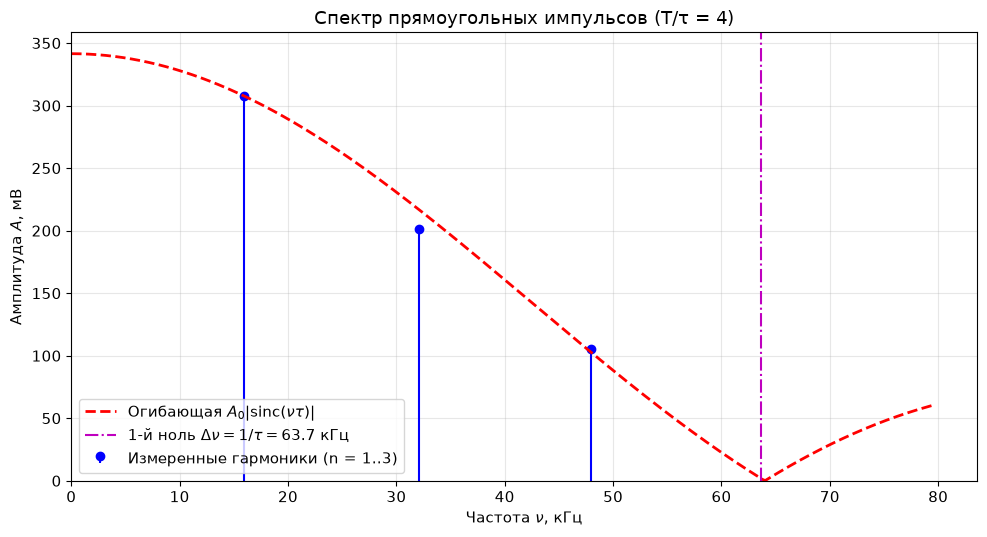

=== Прямоугольные импульсы: T/τ = 1.3333333333333333 (измерено 1.44) ===
 n  freq, kHz  A, mV  (Cn/C1)_эксп  (Cn/C1)_теор(ном)  (Cn/C1)_теор(изм)
 1      15.77 314.90         1.000              1.000              1.000
 2      32.04 206.40         0.655              0.707              0.574
 3      48.02  96.09         0.305              0.333              0.106
Период T = 62.73 мкс, τ_изм = 43.57 мкс
Ширина главного лепестка (1-й ноль): Δν = 21.03 кГц (по T/q: 21.26 кГц)
Соотношение неопределённостей: Δν·τ_ном = 0.99 | Δν·τ_изм = 0.92 (теория = 1.00)


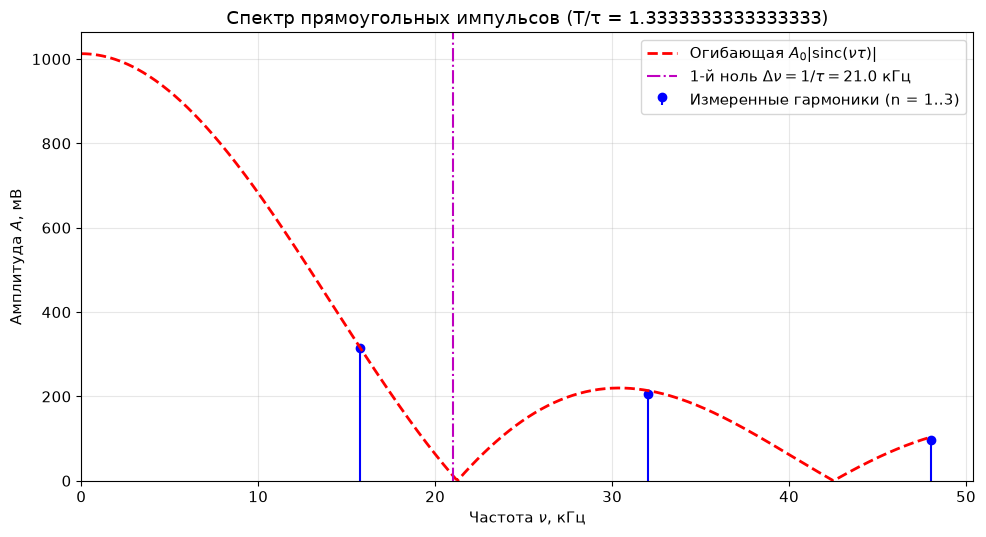

In [28]:
def analyze_rect_train(
    harmonics: pd.DataFrame,
    T: float,
    tau_exp: float,
    q_nominal: float,
) -> None:
    """
    Обработка задачи 2: сравнение относительных амплитуд Cn/C1 с теорией,
    построение огибающей |sinc(ν·τ)| и проверка Δν·τ ≈ 1.
    """
    df = harmonics.copy()
    f1 = float(df.loc[df["n"] == 1, "freq, kHz"].iloc[0])
    A1 = float(df.loc[df["n"] == 1, "A, mV"].iloc[0])

    # Теоретические относительные амплитуды: Cn/C1 = |sinc(n/q)| / |sinc(1/q)|
    q_exp = T / tau_exp
    df["(Cn/C1)_эксп"] = (df["A, mV"] / A1).round(3)
    df["(Cn/C1)_теор(ном)"] = (
        np.abs(np.sinc(df["n"] / q_nominal)) / np.abs(np.sinc(1.0 / q_nominal))
    ).round(3)
    df["(Cn/C1)_теор(изм)"] = (
        np.abs(np.sinc(df["n"] / q_exp)) / np.abs(np.sinc(1.0 / q_exp))
    ).round(3)

    # Ширина главного лепестка (до первого нуля спектра): Δν = 1 / τ
    tau_nom = T / q_nominal
    df_lobe_nom_kHz = 1.0 / (tau_nom * 1e3)      # = q_nominal / T
    df_lobe_spec_kHz = q_nominal * f1            # по частоте 1-й гармоники

    print(f"=== Прямоугольные импульсы: T/τ = {q_nominal} (измерено {q_exp:.2f}) ===")
    print(df.to_string(index=False))
    print(f"Период T = {T*1e6:.2f} мкс, τ_изм = {tau_exp*1e6:.2f} мкс")
    print(
        f"Ширина главного лепестка (1-й ноль): "
        f"Δν = {df_lobe_spec_kHz:.2f} кГц (по T/q: {df_lobe_nom_kHz:.2f} кГц)"
    )
    print(
        f"Соотношение неопределённостей: "
        f"Δν·τ_ном = {(df_lobe_spec_kHz * 1e3) * tau_nom:.2f} | "
        f"Δν·τ_изм = {(df_lobe_spec_kHz * 1e3) * tau_exp:.2f} (теория = 1.00)"
    )

    # Огибающая A(f) = A1 * |sinc(f * tau_nom)| / |sinc(f1 * tau_nom)|
    f_max = max(float(df["freq, kHz"].max()), df_lobe_spec_kHz * 1.25)
    f_grid = np.linspace(0, f_max, 400)
    env_y = A1 * np.abs(np.sinc(f_grid * 1e3 * tau_nom)) / np.abs(
        np.sinc(f1 * 1e3 * tau_nom)
    )

    plot_spectrum(
        df,
        title=f"Спектр прямоугольных импульсов (T/τ = {q_nominal})",
        envelope=Envelope(f_grid, env_y, r"Огибающая $A_0 |\mathrm{sinc}(\nu\tau)|$"),
        vlines=[(df_lobe_spec_kHz, rf"1-й ноль $\Delta\nu = 1/\tau = {df_lobe_spec_kHz:.1f}$ кГц")],
    )


# Пример для T/τ = 4
harm_q4 = pd.DataFrame({
    "n": [1, 2, 3],
    "freq, kHz": [15.92, 32.12, 47.94],
    "A, mV": [307.8, 201.1, 105.0], 
})
T_q4 = 62.5  * 1e-6
tau_q4 = (14.58 - 2.35) * 1e-6

analyze_rect_train(harm_q4, T=T_q4, tau_exp=tau_q4, q_nominal=4)


# Пример для T/τ = 4/3
harm_q43 = pd.DataFrame({
    "n": [1, 2, 3],
    "freq, kHz": [15.77, 32.04, 48.02],
    "A, mV": [314.9, 206.4, 96.09], 
})
T_q43 = 62.73 * 1e-6 
tau_q43 = (46.3 - 2.732) * 1e-6 

analyze_rect_train(harm_q43, T=T_q43, tau_exp=tau_q43, q_nominal=4/3)

**Часть 3. Прохождение сигнала через $RC$-цепочки (АЧХ)**

Паразитная ёмкость C_пар ≈ 83 пФ

=== Скважность T/tau = 4/3 ===
    Цепочка  f_ср эксп, кГц  f_ср теор (C), кГц  f_ср теор (C+C_пар), кГц
C1 = 100 пФ            87.6               159.2                      86.9
C2 = 200 пФ            57.1                79.6                      56.2
C3 = 530 пФ            29.0                30.0                      26.0


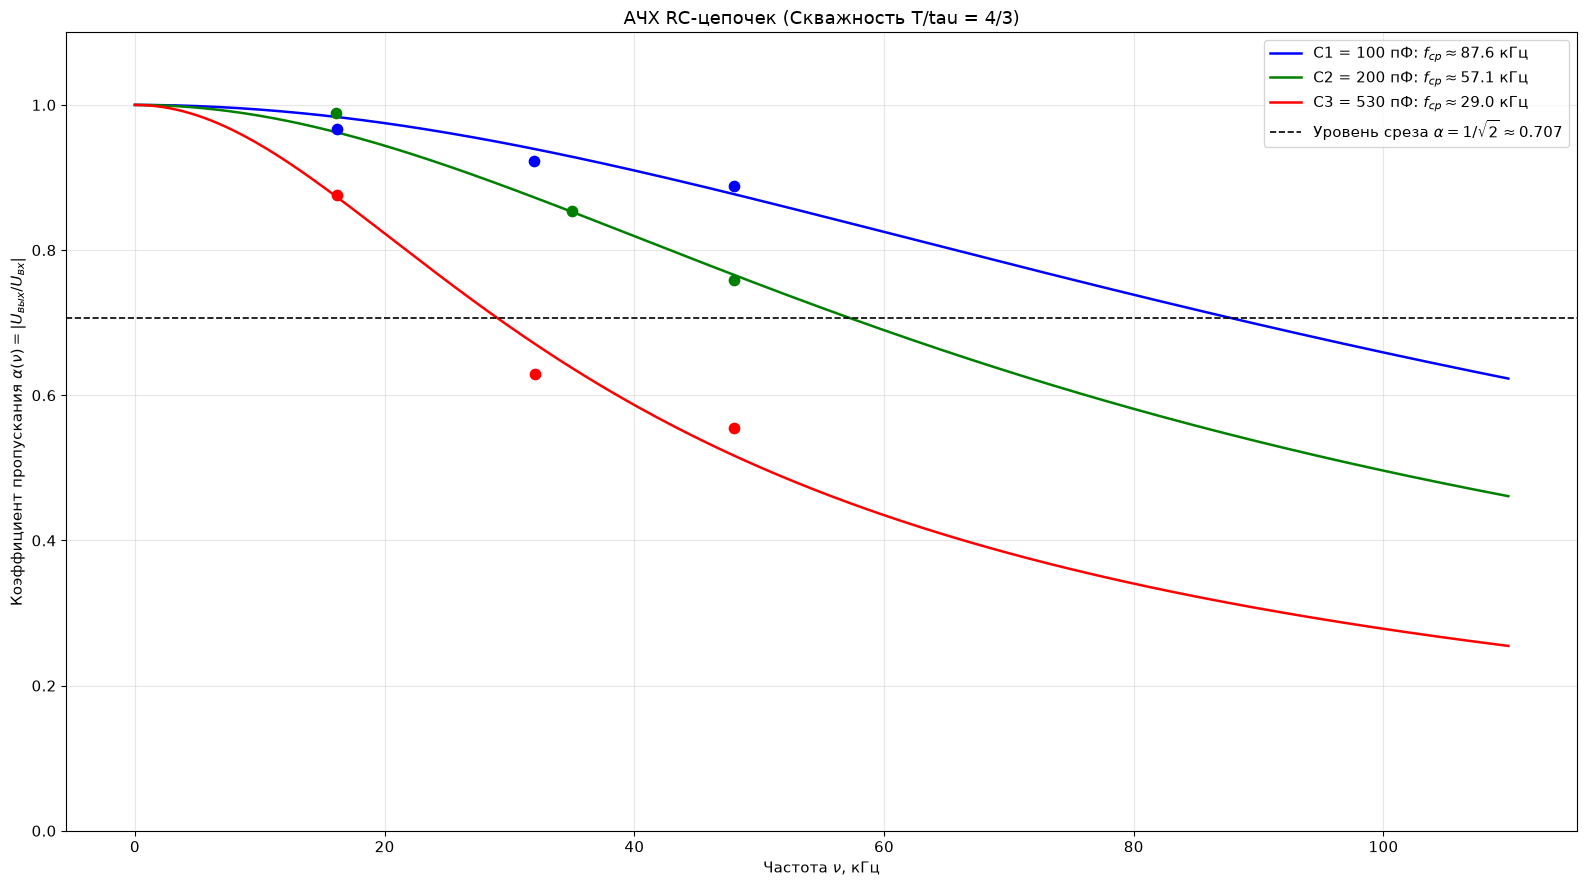


=== Скважность T/tau = 4 (duty = 0.25) ===
    Цепочка  f_ср эксп, кГц  f_ср теор (C), кГц  f_ср теор (C+C_пар), кГц
C1 = 100 пФ            75.9               159.2                      86.9
C2 = 200 пФ            55.1                79.6                      56.2
C3 = 530 пФ            25.3                30.0                      26.0


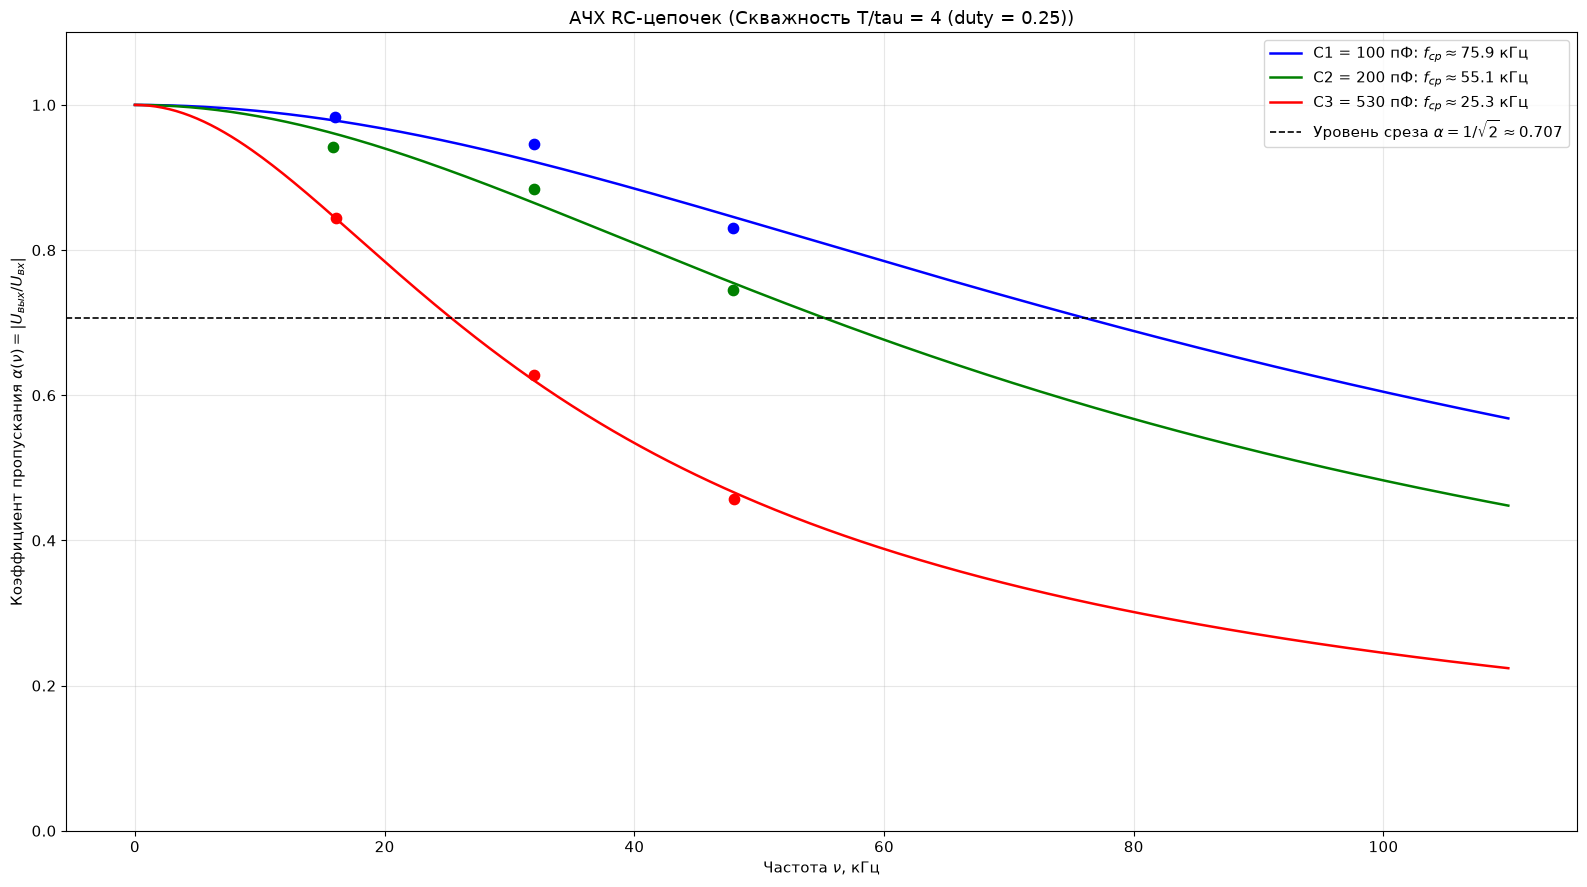

In [29]:
from dataclasses import dataclass
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares

R_OHM = 10e3  # Сопротивление цепочки R = 10 кОм


@dataclass
class ExperimentWithC:
  C: float  # Ёмкость, Ф
  name: str  # Название цепочки для легенды
  harmonics: pd.DataFrame  # Выходной спектр
  A_in: np.ndarray  # Входные амплитуды из Задачи 2, мВ
  T: float  # Период, с

  def get_alpha(self) -> np.ndarray:
    """Коэффициент пропускания |U_вых / U_вх|."""
    return np.asarray(self.harmonics["A, mV"]) / self.A_in

  def theoretical_f_cut_khz(self, c_par: float = 0.0) -> float:
    """Теоретическая частота среза f_ср = 1 / (2π R (C + C_пар)), кГц."""
    return (1.0 / (2.0 * np.pi * R_OHM * (self.C + c_par))) / 1e3

A_IN_DUTY_43 = np.array((314.9, 206.4, 96.09))
A_IN_DUTY_4 = np.array((307.8, 201.1, 105.0))

exp_duty43 = (
    ExperimentWithC(
        C=100e-12,
        name="C1 = 100 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.15, 31.97, 48.02),
            "A, mV": (304.3, 190.4, 85.41),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_43,
        T=(66.17 - 3.879) * 1e-6,
    ),
    ExperimentWithC(
        C=200e-12,
        name="C2 = 200 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.07, 34.97, 48.02),
            "A, mV": (311.4, 176.2, 72.95),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_43,
        T=(107.4 - 43.63) * 1e-6,
    ),
    ExperimentWithC(
        C=530e-12,
        name="C3 = 530 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.15, 32.04, 48.02),
            "A, mV": (275.8, 129.9, 53.38),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_43,
        T=(104.8 - 42.1) * 1e-6,
    ),
)

exp_duty4 = (
    ExperimentWithC(
        C=100e-12,
        name="C1 = 100 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.0, 31.97, 47.94),
            "A, mV": (302.5, 190.4, 87.19),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4,
        T=(58.6 - 0) * 1e-6,
    ),
    ExperimentWithC(
        C=200e-12,
        name="C2 = 200 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (15.85, 31.97, 47.94),
            "A, mV": (290.0, 177.9, 78.29),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4,
        T=(63.4 - 0) * 1e-6,
    ),
    ExperimentWithC(
        C=530e-12,
        name="C3 = 530 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.07, 31.97, 48.02),
            "A, mV": (259.8, 126.3, 48.04),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4[:3],
        T=(73.05 - 9.994) * 1e-6,
    ),
)


def ach_curve(f: np.ndarray, f_cut: float) -> np.ndarray:
  return 1.0 / np.sqrt(1.0 + (f / f_cut) ** 2)

def fit_c_par(blocks) -> float:
    def residuals(p):
        r = []
        for block in blocks:
            for e in block:
                f = np.asarray(e.harmonics["freq, kHz"])
                r += list(ach_curve(f, e.theoretical_f_cut_khz(p[0] * 1e-12)) - e.get_alpha())
        return r
    return least_squares(residuals, [50.0]).x[0] * 1e-12

C_PAR = fit_c_par((exp_duty43, exp_duty4))
print(f"Паразитная ёмкость C_пар ≈ {C_PAR*1e12:.0f} пФ")   # ≈ 85 пФ

def analyze_block(experiments: tuple[ExperimentWithC, ...], title: str) -> None:
  f_grid = np.linspace(0, 110, 400)
  colors = ("b", "g", "r")
  summary = []
  

  plt.figure(figsize=(16,9))

  for exp, color in zip(experiments, colors):
    freq = np.asarray(exp.harmonics["freq, kHz"])
    alpha = exp.get_alpha()

    # Аппроксимация АЧХ для определения частоты среза
    popt, _ = curve_fit(ach_curve, freq, alpha, p0=(50.0,))
    f_cut_exp = float(popt.item(0))
    f_cut_theor = exp.theoretical_f_cut_khz()

    summary.append({
        "Цепочка": exp.name,
        "f_ср эксп, кГц": round(f_cut_exp, 1),
        "f_ср теор (C), кГц": round(f_cut_theor, 1),
        "f_ср теор (C+C_пар), кГц": round(exp.theoretical_f_cut_khz(C_PAR), 1),
    })

    plt.scatter(freq, alpha, color=color, s=55, zorder=3)
    plt.plot(
        f_grid,
        ach_curve(f_grid, f_cut_exp),
        color=color,
        linewidth=1.8,
        label=f"{exp.name}: $f_{{ср}} \\approx {f_cut_exp:.1f}$ кГц",
    )

  plt.axhline(
      1.0 / np.sqrt(2.0),
      color="k",
      linestyle="--",
      linewidth=1.2,
      label=r"Уровень среза $\alpha = 1/\sqrt{2} \approx 0.707$",
  )

  print(f"\n=== {title} ===")
  print(pd.DataFrame(summary).to_string(index=False))

  plt.title(f"АЧХ RC-цепочек ({title})")
  plt.xlabel("Частота $\\nu$, кГц")
  plt.ylabel(r"Коэффициент пропускания $\alpha(\nu) = |U_{вых}/U_{вх}|$")
  plt.ylim(0, 1.1)
  plt.grid(True, alpha=0.3)
  plt.legend()
  plt.tight_layout()
  plt.show()


analyze_block(exp_duty43, "Скважность T/tau = 4/3")
analyze_block(exp_duty4, "Скважность T/tau = 4 (duty = 0.25)")
